In [10]:
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

In [11]:
data=pd.read_csv(r"D:\HOPEAI\ML Resources\Machine Learning-Classification\Week4.0-Machine Learning-Classification\CLassification\1.Traditional Way\Social_Network_Ads.csv")

In [12]:
data.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [13]:
data["Purchased"].value_counts()

Purchased
0    257
1    143
Name: count, dtype: int64

In [14]:
data=pd.get_dummies(data,columns=["Gender"],drop_first=True,dtype=int)

In [15]:
data.head()

,User ID,Age,EstimatedSalary,Purchased,Gender_Male
0,15624510,19,19000,0,1
1,15810944,35,20000,0,1
2,15668575,26,43000,0,0
3,15603246,27,57000,0,0
4,15804002,19,76000,0,1


In [16]:
X=data.drop(columns=["Purchased","User ID"])

In [17]:
y=data["Purchased"]

In [18]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [30]:
knn=KNeighborsClassifier(n_neighbors=4,metric='minkowski',p=2)
knn.fit(X_train,y_train)

,n_neighbors,4
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [31]:
y_pred=knn.predict(X_test)
y_pred

array([0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0], dtype=int64)

In [32]:
from sklearn.metrics import classification_report,confusion_matrix

report=classification_report(y_test,y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.79      0.94      0.86        52
           1       0.83      0.54      0.65        28

    accuracy                           0.80        80
   macro avg       0.81      0.74      0.76        80
weighted avg       0.81      0.80      0.79        80



In [33]:
cm=confusion_matrix(y_test,y_pred)

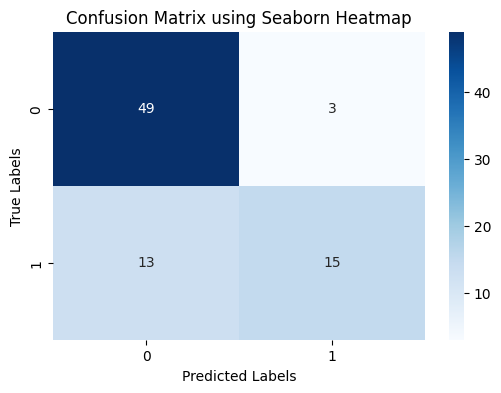

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,4))
sns.heatmap(cm, 
    annot=True,            # Show the numbers inside the blocks
    fmt='d',               # Print numbers as integers 
    cmap='Blues',   )       # Colormap style
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix using Seaborn Heatmap')
plt.show()
